In [1]:
import os
from dotenv import load_dotenv
import json
import random
import matplotlib.pyplot as plt
import numpy as np
import asyncio
import pandas as pd

from benchmarklib import BenchmarkDatabase
from clique import CliqueProblem, CliqueOracleTrial
from benchmarklib.compilers import CompileType, XAGCompiler


from sqlalchemy import select, func
from sqlalchemy.orm import joinedload

In [2]:
benchmark_db = BenchmarkDatabase("clique.db", CliqueProblem, CliqueOracleTrial)

In [3]:
def get_raw_timing_data(db):
    data = {
        'XAG': {},
        'CLASSICAL_FUNCTION': {}
    }
    for num_vars in range(3, 9):
        data['XAG'][num_vars] = []
        data['CLASSICAL_FUNCTION'][num_vars] = []

    with db.session() as session:
        query = select(CliqueProblem.nodes, CliqueOracleTrial.compiler_name, CliqueOracleTrial.extra_data).select_from(CliqueOracleTrial).join(CliqueOracleTrial.problem).where(CliqueOracleTrial.extra_data != None)
        result = session.execute(query).fetchall()
        for row in result:
            num_vars, compiler_name, extra_data = row
            compile_time = extra_data.get('compile_time', None)
            if compile_time is None:
                continue
            if compiler_name == 'XAG':
                data['XAG'][num_vars].append(compile_time)
            elif compiler_name == 'CLASSICAL_FUNCTION':
                data['CLASSICAL_FUNCTION'][num_vars].append(compile_time)

    return data

def average_timing_data(timing_data, mode="mean"):
    averages = {}
    for compiler in timing_data:
        averages[compiler] = {}
        for num_vars in timing_data[compiler]:
            if timing_data[compiler][num_vars]:
                if mode == "mean":
                    averages[compiler][num_vars] = sum(timing_data[compiler][num_vars]) / len(timing_data[compiler][num_vars])
                elif mode == "median":
                    sorted_data = sorted(timing_data[compiler][num_vars])
                    n = len(sorted_data)
                    if n % 2 == 0:
                        averages[compiler][num_vars] = (sorted_data[n // 2 - 1] + sorted_data[n // 2]) / 2
                    else:
                        averages[compiler][num_vars] = sorted_data[n // 2]
    return averages

In [4]:
raw_data = get_raw_timing_data(benchmark_db)

In [8]:
import json
with open("../shared/compile_time_data_clique.json", "w") as f:
    f.write(json.dumps(raw_data))

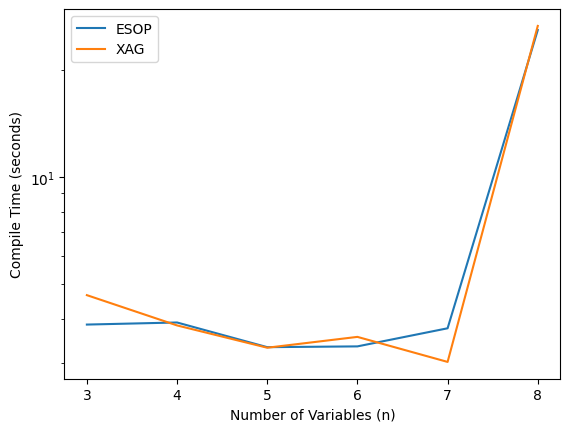

In [20]:
import numpy as np
compiler = "CLASSICAL_FUNCTION"
num_vars_data = range(3, 9)
data = average_timing_data(raw_data, "mean")
esop_mean_data = [data["CLASSICAL_FUNCTION"][n] for n in num_vars_data]
xag_mean_data = [data["XAG"][n] for n in num_vars_data]
plt.plot(num_vars_data, esop_mean_data, label='ESOP')
plt.plot(num_vars_data, xag_mean_data, label='XAG')
plt.xticks(num_vars_data)
plt.xlabel('Number of Variables (n)')
plt.ylabel('Compile Time (seconds)')
plt.yscale('log')
plt.legend()
plt.savefig('plots/Clique_timing_results_mean.png')
plt.show()

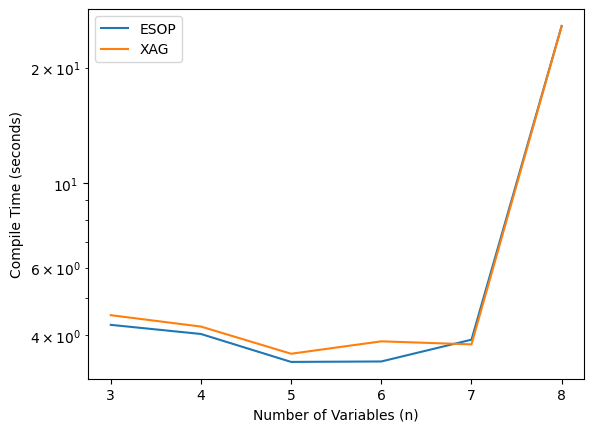

In [19]:
num_vars_data = range(3, 9)
data = average_timing_data(raw_data, "median")
esop_median_data = [data["CLASSICAL_FUNCTION"][n] for n in num_vars_data]
xag_median_data = [data["XAG"][n] for n in num_vars_data]
plt.plot(num_vars_data, esop_median_data, label='ESOP')
plt.plot(num_vars_data, xag_median_data, label='XAG')
plt.xticks(num_vars_data)
plt.xlabel('Number of Variables (n)')
plt.ylabel('Compile Time (seconds)')
plt.yscale('log')
plt.title('')
plt.legend()
plt.savefig('plots/Clique_timing_results_median.png')
plt.show()